# 13. PHM 2018 V3와 TEP의 평가 가능성 비교

    **고장전조기예측(PHM)과고장후이상탐지(TEP)의모델성능순위를비교하지않는다.** 비교하는것은입력기회가없어전체이벤트를포괄하지못하는구조다. PHM값은V3코드·원표에서확인한정수이고,TEP값은가용성조작후3개seed의실측평균이다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/sensor_availability/config.json').exists())
OUT=ROOT/'reports/sensor_availability'
def js(name): return json.loads((OUT/name).read_text(encoding='utf-8'))
def table(name): return pd.read_csv(OUT/'tables'/name)
def show(frame,title):
    display(frame.style.hide(axis='index').set_caption(title).format(precision=5,na_rep='해당 없음')
            .set_properties(**{'padding':'6px 9px','text-align':'left'})
            .set_table_styles([{'selector':'caption','props':[('text-align','left'),('font-weight','bold')]},
                              {'selector':'th','props':[('background-color','#eef3f6'),('text-align','left')]}]))
def figure(name): display(Image(filename=str(OUT/'figures'/name)))
baseline=js('baseline.json')
phm=js('sources/phm_definition_audit.json')
full=table('full_summary.csv')
summary=table('summary_mean_sd.csv')

## 1. 같은 형식으로 분모를 표시

    PHM운영점10:전체194개,가용91개,불가103개,검출33개. 전체검출률17.01%,조건부검출률36.26%다. PHM103/194=53.0928%를TEP목표53.1%(5,310/10,000)로근사했으며서로정확히같은비율은아니다.

dataset,condition,total,available,unavailable,partial,detected,conditional_rate,overall_rate,task
PHM2018 V3,기존 고정 운영점10,194,91.00000,103.00000,해당 없음,33.00000,0.36264,0.17010,"고장 전 [tf-600,tf-60] raw 조기예측"
TEP,평가 불가능 실행 0.0%,10000,10000.00000,0.00000,0.00000,9851.00000,0.98510,0.98510,고장 주입 후40h 이상탐지
TEP,평가 불가능 실행 53.1%,10000,4690.00000,5310.00000,0.00000,4617.33333,0.98451,0.46173,고장 주입 후40h 이상탐지


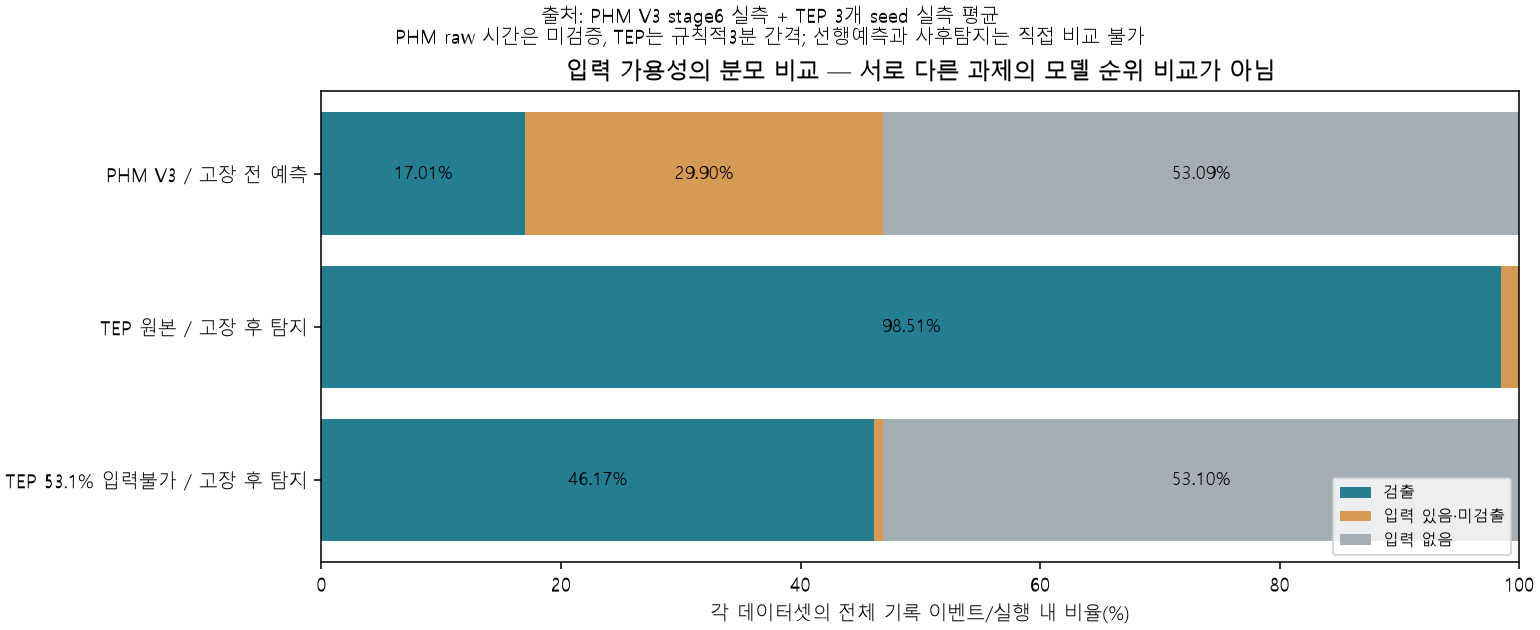

In [2]:
comparison=table('phm_tep_comparison.csv')
show(comparison[['dataset','condition','total','available','unavailable','partial','detected','conditional_rate','overall_rate','task']],
     'PHM V3 원표 vs TEP 가용성실험 / 조건부·전체분모 병기')
figure('phm_tep_availability.png')

## 2. 가용성 계수와 모델 검출률의 곱

    `전체검출률 = 가용실행비율 × 조건부검출률`은두분모의정의에따른산술관계다. TEP원본의조건부성능을유지한다는가정으로Baseline×(1-r)를계산하면실측과가깝다. 이계산은가정에기반한예상값이며,실제seed별균형선택결과를대체하지않는다.

In [3]:
identity=comparison[['dataset','condition','available','total','conditional_rate','overall_rate']].copy()
identity['coverage_factor']=identity.available/identity.total
identity['factor_times_conditional']=identity.coverage_factor*identity.conditional_rate
identity['difference']=identity.overall_rate-identity.factor_times_conditional
assert np.max(np.abs(identity.difference))<1e-12
show(identity,'실측분모관계: 평가가능비율×조건부검출률')
show(summary[['rate','overall_detection_rate','analytical_MCAR_detection_rate']],
     '실제측정평균 vs Baseline×(1-r) 가정계산')

dataset,condition,available,total,conditional_rate,overall_rate,coverage_factor,factor_times_conditional,difference
PHM2018 V3,기존 고정 운영점10,91.00000,194,0.36264,0.17010,0.46907,0.17010,-0.00000
TEP,평가 불가능 실행 0.0%,10000.00000,10000,0.98510,0.98510,1.00000,0.98510,0.00000
TEP,평가 불가능 실행 53.1%,4690.00000,10000,0.98451,0.46173,0.46900,0.46173,-0.00000


rate,overall_detection_rate,analytical_MCAR_detection_rate
0.00000,0.98510,0.98510
0.10000,0.88640,0.88659
0.25000,0.73830,0.73882
0.40000,0.59067,0.59106
0.53100,0.46173,0.46201


## 3. 맞춰 재현한 것과 재현하지 않은 것

    | 항목 | 범위 |
    |---|---|
    | 재현한 의미 | 해당이벤트평가구간에유효입력기회가0개인경우NO_INPUT |
    | PHM 평가구간 | `[tf-600,tf-60] raw`의사전예측anchor; B특징·coverage규칙 |
    | TEP 평가구간 | 고장주입후sample161~960(40h),20×52유효창 |
    | 가정 | TEP고장별균형랜덤실행선정,선택실행은종료까지공백 |
    | 재현하지않음 | PHM실제공백길이분포,장비·공정·고장징후와누락의연관성 |
    | 모델변경 | 없음: 재학습·threshold조정·구조변경없음 |
    | 오경보비교 | PHM전체경보/raw와TEP정상경보/h는정의·단위가달라직접비교불가 |

    입력손실의학습영향은미평가다. 가용미검출을전부분류능력저하로단정하지않는다. 세seed의SD는누락선택변동이며모델일반화의신뢰구간이아니다.

In [4]:
phm_sources=pd.DataFrame([{'참조파일':k,'SHA256':v['sha256']} for k,v in phm['files'].items()])
show(phm_sources,'PHM V3 규칙·결과를읽기전용으로검증한출처')
preservation=js('sources/preservation_check.json')
assert preservation['all_unchanged']
show(pd.DataFrame([{'기존TEP보호파일':preservation['protected_TEP_files'],
                   'PHM참조파일':preservation['protected_PHM_source_files'],
                   '변경없음':preservation['all_unchanged']}]),'기존원본·모델·분할·00~10번노트북보존')

참조파일,SHA256
src/alarm_evaluation.py,27f12ab27081d7eccc86128146485c33e8cf89b820b6ee8fdef0ec6e094a4527
src/final_evaluation.py,4042f45bdd7bd15ccb1f54a558d4abaf0861daf6fc76b0163bb90c3099fc102f
src/features.py,8365e66a464fb222892f9583f756489d60a5c8252cc1a8c33b9d1de2d82043b7
config/preprocessing.json,32d03ddf73d577724efec381492e60104b9d42fc7177dd1646230b88509c8be2
outputs/tables/stage6_holdout_summary.csv,308b0422dd4c0de568f7ed4450f382c477ebac9a4d95e44efd3f18618845305f
outputs/tables/stage6_holdout_events.csv,b86edc44b6dcd18468b2738c4dd7e1fc5e7c89155d2b35f7d19e2dbef22c83ac
reports/19_group_and_holdout.md,a5502ed69a95ba91eb00e755cce49461659248c8e204682cb1507b7ef672cfe7


기존TEP보호파일,PHM참조파일,변경없음
147,7,True


## 4. 재현과 보고서

    [최종 보고서](../../reports/sensor_availability/final_report.md)를참조한다. 실험코드·새노트북은이폴더에,새수치·그림은`reports/sensor_availability/`에만기록했다.

    프로젝트루트에서`experiments/sensor_availability/run.ps1`을실행하면Baseline→PHM감사→마스크검증→파일럿→전체조건→보고서→새노트북순으로진행한다. `-ResultsOnly`는저장된결과의검증·보고서·새노트북만작성한다. 기존분석파일은덮어쓰지않는다.

    출처: PHM2018-Project-V3의stage6실제원표·src평가코드,TEP고정모델의Test예측. [PHM공식과제설명](https://phmsociety.org/conference/annual-conference-of-the-phm-society/annual-conference-of-the-prognostics-and-health-management-society-2018-b/phm-data-challenge-6/)에서사전예측과제임을확인했다.